In [2]:
import uproot
import numpy as np
import awkward as ak
import matplotlib.pyplot as plt

In [3]:
# standard library imports
from __future__ import absolute_import, division, print_function


# standard numerical library imports
import numpy as np
import scipy as sp

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [4]:
! python3 utils.py

In [5]:
import os
import sys

# Adds the current file's directory to the Python path
sys.path.append(os.path.dirname(os.path.abspath("/nfs/pic.es/user/p/pdasgupt/")))

# Now try your import again
# from utils import pdg_from_id, mass_from_pdg

In [6]:
# Global plot settings
from matplotlib import rc
import matplotlib.font_manager
rc('font', family='serif')
rc('text', usetex=False)
rc('font', size=22) 
rc('xtick', labelsize=15) 
rc('ytick', labelsize=15) 
rc('legend', fontsize=15)

In [7]:
last_run = 1

In [8]:
def histo(f1,f2):
    last_run = 1
    file_path = f1
    
    first = True
    
    current_run = 0
    current_event = 0
    events = {}
    with open(file_path, 'r') as file:
        for line in file:
            if first:
                first = False
            else:
                x = line.split()
                if int(x[0]) > current_run:
                    current_run = int(x[0])
                    events[current_run] = {}
                    current_event = 0
                if int(x[1]) > current_event:
                    current_event = int(x[1])
                    events[current_run][current_event] = []
                events[current_run][current_event].append({'id': int(x[2]), 'charge': int(x[3]), 'perweight': float(x[4]), 'position': (float(x[5]), float(x[6]), float(x[7])), 'momentum': (float(x[8]), float(x[9]), float(x[10]), float(x[11])), 'history': int(x[12]), 'production_id': int(x[13]), 'enu': float(x[14])})
    num_runs = len(events)
    
    file_path =  f1
    first = True
    
    current_run = 0
    current_event = 0
    eventid=[]
    ID = []
    Charge = []
    perweight = []
    x_g = []
    y_g = []
    z_g = []
    E_g = []
    px_g = []
    py_g = []
    pz_g = []
    history = []
    production_ID = []
    enu = []
    
    with open(file_path, 'r') as file:
        for line in file:
            if first:
                first = False
            else:
                x = line.split()
                if int(x[0]) > current_run:
                    # print("current_run, (x[0])", x[0],current_run)
                    current_run = int(x[0])
                    current_event = 0
                if current_run != last_run:
                    continue
                if int(x[1]) > current_event:
                    # print("current_event, (x[1])", x[1],current_event)  
                    current_event = int(x[1])
                    perweight.append(float(x[4]))
                    production_ID.append(int(x[13]))
                    enu.append(float(x[14]))
                    eventid.append([])
                    ID.append([])
                    Charge.append([])
                    x_g.append([])
                    y_g.append([])
                    z_g.append([])
                    E_g.append([])
                    px_g.append([])
                    py_g.append([])
                    pz_g.append([])
                    history.append([])
                eventid[-1].append(current_event)
                ID[-1].append(int(x[2]))
                Charge[-1].append(int(x[3]))
                x_g[-1].append(float(x[5]))
                y_g[-1].append(float(x[6]))
                z_g[-1].append(float(x[7]))
                E_g[-1].append(float(x[8]))
                px_g[-1].append(float(x[9]))
                py_g[-1].append(float(x[10]))
                pz_g[-1].append(float(x[11]))
                history[-1].append(float(x[12]))
    eventid=ak.Array(eventid)            
    ID = ak.Array(ID)
    Charge = ak.Array(Charge)
    perweight_g = ak.Array(perweight)
    x_g = ak.Array(x_g)
    y_g = ak.Array(y_g)
    z_g = ak.Array(z_g)
    E_g = ak.Array(E_g)
    px_g = ak.Array(px_g)
    py_g = ak.Array(py_g)
    pz_g = ak.Array(pz_g)
    history = ak.Array(history)
    production_ID = ak.Array(production_ID)
    enu = ak.Array(enu)
    
    file_path2 = f2
    first = True
    
    current_run = 0
    current_event = 0
    init_id=[]
    init_charge=[]
    init_x = []
    init_y = []
    init_z = []
    init_E = []
    init_px = []
    init_py = []
    init_pz = []
    init_event_number = []
    init_perweight = []
    
    with open(file_path2, 'r') as file:
        for line in file:
            if first:
                first = False
            else:
                x = line.split()
                init_id.append(int(x[3]))
                init_charge.append(int(x[4]))                
                init_E.append(float(x[8]))
                init_px.append(float(x[9]))
                init_py.append(float(x[10]))
                init_pz.append(float(x[11][:-1]))
                init_x.append(float(x[12]))
                init_y.append(float(x[13]))
                init_z.append(float(x[14][:-1]))
                init_event_number.append(int(x[16][:-1]))
                init_perweight.append(float(x[19]))
    init_id= ak.Array(init_id[:])   
    init_charge= ak.Array(init_id[:])                
    init_E = ak.Array(init_E[:])
    init_px = ak.Array(init_px[:])
    init_py = ak.Array(init_py[:])
    init_pz = ak.Array(init_pz[:])
    init_x = ak.Array(init_x[:])
    init_y = ak.Array(init_z[:])
    init_z = ak.Array(init_z[:])
    init_event_number = ak.Array(init_event_number[:])
    init_perweight = ak.Array(init_perweight[:]) 

    init_id_mod=np.zeros(np.max(np.unique(ak.flatten(eventid))))
    init_ch_mod=np.zeros(np.max(np.unique(ak.flatten(eventid))))
    init_E_mod=np.zeros(np.max(np.unique(ak.flatten(eventid))))
    init_px_mod=np.zeros(np.max(np.unique(ak.flatten(eventid))))
    init_py_mod=np.zeros(np.max(np.unique(ak.flatten(eventid))))
    init_pz_mod=np.zeros(np.max(np.unique(ak.flatten(eventid))))
    init_x_mod=np.zeros(np.max(np.unique(ak.flatten(eventid))))
    init_y_mod=np.zeros(np.max(np.unique(ak.flatten(eventid))))
    init_z_mod=np.zeros(np.max(np.unique(ak.flatten(eventid))))
    init_perweight_mod=np.zeros(np.max(np.unique(ak.flatten(eventid))))
    init_id_mod[init_event_number-1]=init_id
    init_ch_mod[init_event_number-1]=init_charge    
    init_E_mod[init_event_number-1]=init_E
    init_px_mod[init_event_number-1]=init_px
    init_py_mod[init_event_number-1]=init_py
    init_pz_mod[init_event_number-1]=init_pz
    init_x_mod[init_event_number-1]=init_x
    init_y_mod[init_event_number-1]=init_y
    init_z_mod[init_event_number-1]=init_z
    init_perweight_mod[init_event_number-1]=init_perweight
    len(production_ID)
    Q2_g = - (enu-E_g[:,0])**2 + px_g[:,0]**2 + py_g[:,0]**2 + (enu-pz_g[:,0])**2
    
    W_g = np.sqrt((enu-E_g[:,0]+E_g[:,1])**2 - (-px_g[:,0]+px_g[:,1])**2 - (-py_g[:,0]+py_g[:,1])**2 - (enu-pz_g[:,0]+pz_g[:,1])**2)
    
    costheta_g = pz_g / np.sqrt(px_g**2 + py_g**2 + pz_g**2)
    
    perweight = perweight_g*1e-38
    
    final = ak.local_index(ID, axis=1) != 1
    chase_g = ak.local_index(ID, axis=1) != 1
    pdg_to_mass = {
        13: 0.10566,
        14: 0,
    
        22: 0,
    
        130: 0.49761,
        310: 0.49761,
    
        111: 0.13498,
        211: 0.13957,
    
        221: 0.54785,
        223: 0.78265,
    
        311: 0.49761,
        321: 0.49368,
    
        2112: 0.93957,
        2212: 0.93827,
    
        1114: 1.232,
        2114: 1.232,
        2214: 1.232,
        2224: 1.232,
    
        3122: 1.1157,
    
        3112: 1.1974,
        3212: 1.1926,
        3222: 1.1894,
    
        3312: 1.3217,
        3322: 1.3149,
    }
    ID_to_pdg = {
        # Nucleons resonance
        (1,+0): 2112,
        (1,+1): 2212,
    
        (2,-1): 1114,
        (2,+0): 2114,
        (2,+1): 2214,
        (2,2): 2224,
        
        (3,+0): 202112,
        (3,+1): 202212,
    
        (4,+0): 102112,
        (4,+1): 102212,
    
        (5,+0): 122112,
        (5,+1): 122212,
    
        (7,+0): 102114,
        (7,+1): 102214,
    
        (8,+0): 112114,
        (8,+1): 112214,
    
        (10,+0): 102116,
        (10,+1): 102216,
    
        (12,+0): 212112,
        (12,+1): 212212,
    
        (14,+0): 212114,
        (14,+1): 212214,
    
        (16,+0): 202116,
        (16,+1): 202216,
    
        (19,-1): 111112,
        (19,+0): 112112,
        (19,+1): 112212,
        (19,+2): 112222,
    
        (21,-1): 121114,
        (21,+0): 122114,
        (21,+1): 122214,
        (21,+2): 122224,
    
        (26,-1): 221112,
        (26,+0): 222112,
        (26,+1): 222212,
        (26,+2): 222222,
    
        (27,-1): 201114,
        (27,+0): 202114,
        (27,+1): 202214,
        (27,+2): 202224,
    
        (28,-1): 221114,
        (28,+0): 222114,
        (28,+1): 222214,
        (28,+2): 222224,
    
        (30,-1): 211116,
        (30,+0): 212116,
        (30,+1): 212216,
        (30,+2): 212226,
        
        (31,-1): 201118,
        (31,+0): 202118,
        (31,+1): 202218,
        (31,+2): 202228,
    
        # Baryons with strangeness s=-1
        (32,+0): 3122,
    
        (33,-1): 3112,
        (33,+0): 3212,
        (33,+1): 3222,
    
        (34,-1): 3114,
        (34,+0): 3214,
        (34,+1): 3224,
    
        (35,+0): 102132,
        (36,+0): 102134,
        (37,+0): 203122,
        (38,+0): 103122,
        (39,+0): 103124,
        (40,+0): 213122,
        (41,+0): 203126,
        (42,+0): 103126,
    
        (43,-1): 103114,
        (43,+0): 103214,
        (43,+1): 103224,
    
        (44,-1): 103116,
        (44,+0): 103216,
        (44,+1): 103226,
    
        (45,-1): 203118,
        (45,+0): 203218,
        (45,+1): 203228,
    
        (46,+0): 123122,
        (47,+0): 213124,
    
        (50,-1): 203112,
        (50,+0): 203212,
        (50,+1): 203222,
    
        (51,-1): 113112,
        (51,+0): 113212,
        (51,+1): 113222,
    
        (52,-1): 203116,
        (52,+0): 203216,
        (52,+1): 203226,
    
        # Baryons with strangeness s=-2
        (53,-1): 3312,
        (53,+0): 3322,
    
        (54,-1): 3314,
        (54,+0): 3324,
    
        # Baryons with strangeness s=-3
        (55,-1): 3334,
    
        # Baryons with charm c=+1
        (56,+1): 4122,
    
        (57,+0): 4112,
        (57,+1): 4212,
        (57,+2): 4222,
    
        (58,+0): 4114,
        (58,+1): 4214,
        (58,+2): 4224,
    
        (59,+0): 4132,
        (59,+1): 4232,
    
        (60,+0): 4314,
        (60,+1): 4324,
    
        (61,+0): 4332,
    
        # Mesons
        (101,-1): -211,
        (101,+0): +111,
        (101,+1): +211,
    
        (102,+0): 221,
    
        (103,-1): -213,
        (103,+0): +113,
        (103,+1): +213,
    
        (104, +0): 9000221,
        (105, +0): 223,
        (106, +0): 331,
        (107, +0): 333,
        (108, +0): 441,
        (109, +0): 443,
    
        (110,+0): 311,
        (110,+1): 321,
        
        (111,-1): -321,
        (111,+0): -311,
    
        (112,+0): 313,
        (112,+1): 323,
    
        (113,-1): -323,
        (113,+0): -313,
    
        (114,+0): 411,
        (114,+1): 421,
    
        (115,-1): -421,
        (115,+0): -411,
    
        (116,+0): 413,
        (116,+1): 423,
    
        (117,-1): -423,
        (117,+0): -413,
        
        (118,+1): 431,
        (119,-1): -431,
        (120,+1): 433,
        (121,-1): -433,
        (122,+0): 225,
    
        # Leptons
        (901,-1): 11,
        (902,-1): 13,
        (903,-1): 15,
        
        (911,+0): 12,
        (912,+0): 14,
        (913,+0): 16,
    
        # Gauge bosons
        (997,-1): -24,
        (997,+1): 24,
        (998,+0): 23,
        (999,+0): 22,
    
        # Antiparticles
        (-1,+0): -2112,
        (-1,-1): -2212,
    }
    
    def mass_from_pdg(PDG):
        """
        Determine masses of particles from PDG ID
        
        **Arguments**
        - **PDG** An awkward array of PDG ID
    
        **Returns**
    
        - awkward array of same dimension containing the masses of the particles
        """
        pdg_flatten = np.abs(ak.flatten(PDG))
        
        res = ak.to_numpy(ak.zeros_like(ak.values_astype(pdg_flatten, 'float64')))
        for (i, val) in pdg_to_mass.items():
            mask = (pdg_flatten == i)
            res[mask] = val
    
        remaining = np.unique(pdg_flatten[(res==0) & ~((pdg_flatten==12)|(pdg_flatten==14)|(pdg_flatten==16)|(pdg_flatten==22))])
        if len(remaining) > 0:
            print(f"Unassigned masses : {remaining}")
        return ak.unflatten(res, ak.num(PDG))
    # GiBUU particles that have no PDG equivalent
    no_PDG = [6, 9, 11, 13, 15, 17, 18, 20, 22, 23, 24, 25, 29, 48, 49]
    
    def pdg_from_id(ID, Charge):
        """
        Determine PDG id from GiBUU ID and charge of particles
        
        **Arguments**
        - **ID** An awkward array of GiBUU particle ID
    
        - **Charge** An awkward array of particle charges of same shape as ID
    
        **Returns**
    
        - awkward array of same dimension containing PDG id of particles
        """
        ID_flatten = ak.flatten(ID)
        Charge_flatten = ak.flatten(Charge)
        
        res= ak.to_numpy(ak.zeros_like(Charge_flatten))
        for ((i, charge), val) in ID_to_pdg.items():
            mask = (ID_flatten == i) & (Charge_flatten == charge)
            res[mask] = val
        for i in no_PDG:
            errors = Charge_flatten[ID_flatten==i]
            if len(errors) > 0:
                for c in errors:
                    print(f"Particle with ID {i} and charge {c} has no PDG")
        mask = res==0
        masked_id = ID_flatten[mask]
        masked_charge = Charge_flatten[mask]
        remaining = np.column_stack((masked_id, masked_charge))
        uniques = np.unique(remaining, axis=0)
        for (i,c) in uniques:
            print(f"! No pdg found for particle with ID {i} and charge {c}")
        return ak.unflatten(res, ak.num(ID))
    
    
    
    ## Determine masses of particles according to pdg
    
    
    pdg_g = pdg_from_id(ID, Charge)
    
    mass_g = mass_from_pdg(pdg_g)
    # print(mass_g)
    Ekin_g = E_g - mass_g
    def get_1_p_events(pdg,chase,Ekin,init_perweight,perweight):
        pdg_protons = pdg[((pdg == 2212) &(chase==1) &  (Ekin >0.))]
        pdg_hadrons = pdg[((pdg > 99) &(chase==1))]
        flag = abs(init_perweight-perweight) < .0001
        return (ak.num(pdg_protons)==1) & (ak.num(pdg_hadrons)==1) & flag==True
    mask = get_1_p_events(pdg_g, chase_g, Ekin_g, init_perweight_mod,perweight_g) 
    deviation = np.nan_to_num(np.arccos((px_g[mask][:,2] * init_px_mod[mask] + py_g[mask][:,2] * init_py_mod[mask] + pz_g[mask][:,2] * init_pz_mod[mask]) / (np.sqrt(
        (px_g[mask][:,2] ** 2 + py_g[mask][:,2] ** 2 + pz_g[mask][:,2] ** 2)) * np.sqrt(
        (init_px_mod[mask]**2 + init_py_mod[mask]**2 + init_pz_mod[mask]**2)))),0)
    N = 20
    bins = np.linspace(0,1.5,N+1)
    p = bins[1] - bins[0]
    bins_mid = np.arange(0.1,N*p+0.1,p)
    case_1 = Ekin_g[mask][:,2][deviation < 15*180/np.pi]
    
    # case_1_hist = np.histogram(case_1, bins=bins, weights=perweight_g[mask][deviation < 5*180/np.pi])[0]
    case_1_hist = np.histogram(case_1, bins=bins)[0]
    
    case_2 = Ekin_g[mask][:,2][history[mask][:,2]==0]
    
    # case_2_hist = np.histogram(case_2, bins=bins, weights=perweight_g[mask][history[mask][:,2]==0])[0]
    case_2_hist = np.histogram(case_2, bins=bins)[0]
    
    denominator = init_E_mod[(init_id_mod==1)&(init_ch_mod==1)&(abs(init_perweight_mod-perweight_g) < .0001)] - 0.93827
    denominator_hist = np.histogram(denominator, bins=bins)[0]
    
    # denominator_hist = np.histogram(denominator, bins=bins, weights= perweight_g[init_event_number-1<9500][abs(perweight/(10**-45)-perweight2*10**7) < .0001])[0]
    return bins_mid, case_1_hist , case_2_hist, denominator_hist
    # return eventid, init_perweight_mod


In [9]:
x=histo('/data/neutrinos/scratch/pingal/GiBUU2023/release2023/case2/1/FinalEvents.dat','/data/neutrinos/scratch/pingal/GiBUU2023/release2023/case2/1/PertParticles_Init_ALL.dat')

/nfs/pic.es/user/p/pdasgupt/.local/lib/python3.14/site-packages/awkward/_nplikes/array_module.py:300: RuntimeWarning: invalid value encountered in arccos
  return impl(*broadcasted_args, **(kwargs or {}))


In [10]:
x

(array([0.1  , 0.175, 0.25 , 0.325, 0.4  , 0.475, 0.55 , 0.625, 0.7  ,
        0.775, 0.85 , 0.925, 1.   , 1.075, 1.15 , 1.225, 1.3  , 1.375,
        1.45 , 1.525]),
 <Array [1224, 1307, 1118, 841, 593, 333, ..., 9, 8, 3, 5, 6] type='20 * int64'>,
 <Array [1222, 1306, 1118, 841, 593, 333, ..., 9, 8, 3, 5, 6] type='20 * int64'>,
 array([1718, 2275, 1906, 1433, 1070,  684,  443,  304,  186,  125,   72,
          66,   55,   38,   30,   18,   14,   16,   10,    9]))

In [11]:
np.sum(x[1])/np.sum(x[3])

np.float64(0.5830786860198625)

In [12]:
len(np.sort(x[1])),len(np.arange(1,10094,1))

(20, 10093)

In [13]:
x=histo('/data/neutrinos/scratch/pingal/GiBUU2023/release2023/case2/5/FinalEvents.dat','/data/neutrinos/scratch/pingal/GiBUU2023/release2023/case2/5/PertParticles_Init_ALL.dat')

In [11]:
x

(array([0.1 , 0.25, 0.4 , 0.55, 0.7 , 0.85, 1.  , 1.15, 1.3 , 1.45]),
 <Array [3.81, 0, 2.25, 0, 0, 0, 0, 0.611, 0, 0] type='10 * float64'>,
 <Array [2, 0, 2, 0, 0, 0, 0, 1, 0, 0] type='10 * int64'>,
 <Array [3.45, 1.16, 1.24, 0.168, 0, ..., 0.517, 0.13, 0, 0] type='10 * float64'>)

In [ ]:
a=[]
for i in range(1,1001):
    a.append(histo('/data/neutrinos/scratch/pingal/GiBUU2023/release2023/case2/'+str(i)+'/FinalEvents.dat','/data/neutrinos/scratch/pingal/GiBUU2023/release2023/case2/'+str(i)+'/PertParticles_Init_ALL.dat'))
    

Text(0.5, 0, 'Leading proton Kinetic energy [GeV]')

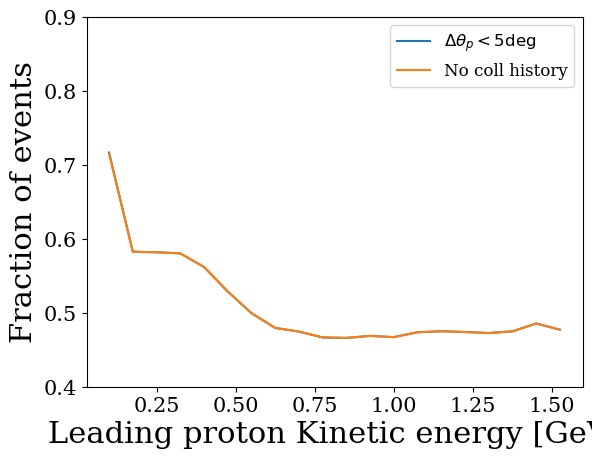

In [27]:
A=np.array(a)
x=np.zeros(len(A[:,2][0]))
y=np.zeros(len(A[:,2][0]))
z=np.zeros(len(A[:,2][0]))
for i in range(1000):
    x=x+(A[:,1][i])
    y=y+(A[:,2][i])
    z=z+(A[:,3][i])
plt.plot(A[:,0][0],x/z,label=r"$\Delta \theta_p <5\deg$")    
# plt.plot(A[:,0][0],y/z,label="No coll history")
plt.ylim(0.4,0.9)
plt.legend(fontsize=12)
plt.ylabel('Fraction of events')
plt.xlabel('Leading proton Kinetic energy [GeV]')

In [165]:
x/1000

array([0.78035819, 0.61375743, 0.58101601, 0.56117511, 0.5343731 ,
       0.4998063 , 0.47260096, 0.45467302, 0.44252472, 0.43487943,
       0.42981861, 0.42429859, 0.4249407 , 0.42458995, 0.42174851,
       0.42584045, 0.41806552, 0.42601483, 0.43171749,        nan])

In [16]:
z

array([3977914., 2679459., 1312297.,  550079.,  241270.,  131724.,
         77983.,   47373.,   29512.,   18460.])

In [38]:
def test(f1,f2):
    last_run = 1
    file_path = f1
    
    first = True
    
    current_run = 0
    current_event = 0
    events = {}
    with open(file_path, 'r') as file:
        for line in file:
            if first:
                first = False
            else:
                x = line.split()
                if int(x[0]) > current_run:
                    current_run = int(x[0])
                    events[current_run] = {}
                    current_event = 0
                if int(x[1]) > current_event:
                    current_event = int(x[1])
                    events[current_run][current_event] = []
                events[current_run][current_event].append({'id': int(x[2]), 'charge': int(x[3]), 'perweight': float(x[4]), 'position': (float(x[5]), float(x[6]), float(x[7])), 'momentum': (float(x[8]), float(x[9]), float(x[10]), float(x[11])), 'history': int(x[12]), 'production_id': int(x[13]), 'enu': float(x[14])})
    num_runs = len(events)
    
    file_path =  f1
    first = True
    
    current_run = 0
    current_event = 0
    
    ID = []
    Charge = []
    perweight = []
    x_g = []
    y_g = []
    z_g = []
    E_g = []
    px_g = []
    py_g = []
    pz_g = []
    history = []
    production_ID = []
    enu = []
    
    
    with open(file_path, 'r') as file:
        for line in file:
            if first:
                first = False
            else:
                x = line.split()
                if int(x[0]) > current_run:
                    current_run = int(x[0])
                    current_event = 0
                if current_run != last_run:
                    continue
                if int(x[1]) > current_event:
                    current_event = int(x[1])
                    perweight.append(float(x[4]))
                    production_ID.append(int(x[13]))
                    enu.append(float(x[14]))
                    ID.append([])
                    Charge.append([])
                    x_g.append([])
                    y_g.append([])
                    z_g.append([])
                    E_g.append([])
                    px_g.append([])
                    py_g.append([])
                    pz_g.append([])
                    history.append([])
                ID[-1].append(int(x[2]))
                Charge[-1].append(int(x[3]))
                x_g[-1].append(float(x[5]))
                y_g[-1].append(float(x[6]))
                z_g[-1].append(float(x[7]))
                E_g[-1].append(float(x[8]))
                px_g[-1].append(float(x[9]))
                py_g[-1].append(float(x[10]))
                pz_g[-1].append(float(x[11]))
                history[-1].append(float(x[12]))
    
    ID = ak.Array(ID)
    Charge = ak.Array(Charge)
    perweight_g = ak.Array(perweight)
    x_g = ak.Array(x_g)
    y_g = ak.Array(y_g)
    z_g = ak.Array(z_g)
    E_g = ak.Array(E_g)
    px_g = ak.Array(px_g)
    py_g = ak.Array(py_g)
    pz_g = ak.Array(pz_g)
    history = ak.Array(history)
    production_ID = ak.Array(production_ID)
    enu = ak.Array(enu)
    
    file_path2 = f2
    first = True
    
    current_run = 0
    current_event = 0
    
    init_x = []
    init_y = []
    init_z = []
    init_E = []
    init_px = []
    init_py = []
    init_pz = []
    
    init_event_number = []
    init_perweight = []
    
    with open(file_path2, 'r') as file:
        for line in file:
            if first:
                first = False
            else:
                x = line[44:].split()
                init_E.append(float(x[8-8]))
                init_px.append(float(x[9-8]))
                init_py.append(float(x[10-8]))
                init_pz.append(float(x[11-8][:-1]))
                init_x.append(float(x[12-8]))
                init_y.append(float(x[13-8]))
                init_z.append(float(x[14-8][:-1]))
                init_event_number.append(int(x[16-8][:-1]))
                init_perweight.append(float(x[19-8]))
    init_E = ak.Array(init_E[1:])
    init_px = ak.Array(init_px[1:])
    init_py = ak.Array(init_py[1:])
    init_pz = ak.Array(init_pz[1:])
    init_x = ak.Array(init_x[1:])
    init_y = ak.Array(init_z[1:])
    init_z = ak.Array(init_z[1:])
    init_event_number = ak.Array(init_event_number[1:])
    init_perweight = ak.Array(init_perweight[1:]) 
    ID = ID[init_event_number-1<9500]
    Charge = Charge[init_event_number-1<9500]
    perweight = init_perweight[init_event_number-1<9500]
    perweight2 = perweight_g[init_event_number-1<9500]    
    x_g = x_g[init_event_number-1<9500]
    y_g = y_g[init_event_number-1<9500]
    z_g = z_g[init_event_number-1<9500]
    E_g = E_g[init_event_number-1<9500]
    px_g = px_g[init_event_number-1<9500]
    py_g = py_g[init_event_number-1<9500]
    pz_g = pz_g[init_event_number-1<9500]
    history = history[init_event_number-1<9500]
    production_ID = production_ID[init_event_number-1<9500]
    enu = enu[init_event_number-1<9500]
    len(production_ID)
    Q2_g = - (enu-E_g[:,0])**2 + px_g[:,0]**2 + py_g[:,0]**2 + (enu-pz_g[:,0])**2
    
    W_g = np.sqrt((enu-E_g[:,0]+E_g[:,1])**2 - (-px_g[:,0]+px_g[:,1])**2 - (-py_g[:,0]+py_g[:,1])**2 - (enu-pz_g[:,0]+pz_g[:,1])**2)
    
    costheta_g = pz_g / np.sqrt(px_g**2 + py_g**2 + pz_g**2)
    
    perweight = perweight*1e-38
    
    final = ak.local_index(ID, axis=1) != 1
    chase_g = ak.local_index(ID, axis=1) != 1
    pdg_to_mass = {
        13: 0.10566,
        14: 0,
    
        22: 0,
    
        130: 0.49761,
        310: 0.49761,
    
        111: 0.13498,
        211: 0.13957,
    
        221: 0.54785,
        223: 0.78265,
    
        311: 0.49761,
        321: 0.49368,
    
        2112: 0.93957,
        2212: 0.93827,
    
        1114: 1.232,
        2114: 1.232,
        2214: 1.232,
        2224: 1.232,
    
        3122: 1.1157,
    
        3112: 1.1974,
        3212: 1.1926,
        3222: 1.1894,
    
        3312: 1.3217,
        3322: 1.3149,
    }
    ID_to_pdg = {
        # Nucleons resonance
        (1,+0): 2112,
        (1,+1): 2212,
    
        (2,-1): 1114,
        (2,+0): 2114,
        (2,+1): 2214,
        (2,2): 2224,
        
        (3,+0): 202112,
        (3,+1): 202212,
    
        (4,+0): 102112,
        (4,+1): 102212,
    
        (5,+0): 122112,
        (5,+1): 122212,
    
        (7,+0): 102114,
        (7,+1): 102214,
    
        (8,+0): 112114,
        (8,+1): 112214,
    
        (10,+0): 102116,
        (10,+1): 102216,
    
        (12,+0): 212112,
        (12,+1): 212212,
    
        (14,+0): 212114,
        (14,+1): 212214,
    
        (16,+0): 202116,
        (16,+1): 202216,
    
        (19,-1): 111112,
        (19,+0): 112112,
        (19,+1): 112212,
        (19,+2): 112222,
    
        (21,-1): 121114,
        (21,+0): 122114,
        (21,+1): 122214,
        (21,+2): 122224,
    
        (26,-1): 221112,
        (26,+0): 222112,
        (26,+1): 222212,
        (26,+2): 222222,
    
        (27,-1): 201114,
        (27,+0): 202114,
        (27,+1): 202214,
        (27,+2): 202224,
    
        (28,-1): 221114,
        (28,+0): 222114,
        (28,+1): 222214,
        (28,+2): 222224,
    
        (30,-1): 211116,
        (30,+0): 212116,
        (30,+1): 212216,
        (30,+2): 212226,
        
        (31,-1): 201118,
        (31,+0): 202118,
        (31,+1): 202218,
        (31,+2): 202228,
    
        # Baryons with strangeness s=-1
        (32,+0): 3122,
    
        (33,-1): 3112,
        (33,+0): 3212,
        (33,+1): 3222,
    
        (34,-1): 3114,
        (34,+0): 3214,
        (34,+1): 3224,
    
        (35,+0): 102132,
        (36,+0): 102134,
        (37,+0): 203122,
        (38,+0): 103122,
        (39,+0): 103124,
        (40,+0): 213122,
        (41,+0): 203126,
        (42,+0): 103126,
    
        (43,-1): 103114,
        (43,+0): 103214,
        (43,+1): 103224,
    
        (44,-1): 103116,
        (44,+0): 103216,
        (44,+1): 103226,
    
        (45,-1): 203118,
        (45,+0): 203218,
        (45,+1): 203228,
    
        (46,+0): 123122,
        (47,+0): 213124,
    
        (50,-1): 203112,
        (50,+0): 203212,
        (50,+1): 203222,
    
        (51,-1): 113112,
        (51,+0): 113212,
        (51,+1): 113222,
    
        (52,-1): 203116,
        (52,+0): 203216,
        (52,+1): 203226,
    
        # Baryons with strangeness s=-2
        (53,-1): 3312,
        (53,+0): 3322,
    
        (54,-1): 3314,
        (54,+0): 3324,
    
        # Baryons with strangeness s=-3
        (55,-1): 3334,
    
        # Baryons with charm c=+1
        (56,+1): 4122,
    
        (57,+0): 4112,
        (57,+1): 4212,
        (57,+2): 4222,
    
        (58,+0): 4114,
        (58,+1): 4214,
        (58,+2): 4224,
    
        (59,+0): 4132,
        (59,+1): 4232,
    
        (60,+0): 4314,
        (60,+1): 4324,
    
        (61,+0): 4332,
    
        # Mesons
        (101,-1): -211,
        (101,+0): +111,
        (101,+1): +211,
    
        (102,+0): 221,
    
        (103,-1): -213,
        (103,+0): +113,
        (103,+1): +213,
    
        (104, +0): 9000221,
        (105, +0): 223,
        (106, +0): 331,
        (107, +0): 333,
        (108, +0): 441,
        (109, +0): 443,
    
        (110,+0): 311,
        (110,+1): 321,
        
        (111,-1): -321,
        (111,+0): -311,
    
        (112,+0): 313,
        (112,+1): 323,
    
        (113,-1): -323,
        (113,+0): -313,
    
        (114,+0): 411,
        (114,+1): 421,
    
        (115,-1): -421,
        (115,+0): -411,
    
        (116,+0): 413,
        (116,+1): 423,
    
        (117,-1): -423,
        (117,+0): -413,
        
        (118,+1): 431,
        (119,-1): -431,
        (120,+1): 433,
        (121,-1): -433,
        (122,+0): 225,
    
        # Leptons
        (901,-1): 11,
        (902,-1): 13,
        (903,-1): 15,
        
        (911,+0): 12,
        (912,+0): 14,
        (913,+0): 16,
    
        # Gauge bosons
        (997,-1): -24,
        (997,+1): 24,
        (998,+0): 23,
        (999,+0): 22,
    
        # Antiparticles
        (-1,+0): -2112,
        (-1,-1): -2212,
    }
    
    def mass_from_pdg(PDG):
        """
        Determine masses of particles from PDG ID
        
        **Arguments**
        - **PDG** An awkward array of PDG ID
    
        **Returns**
    
        - awkward array of same dimension containing the masses of the particles
        """
        pdg_flatten = np.abs(ak.flatten(PDG))
        
        res = ak.to_numpy(ak.zeros_like(ak.values_astype(pdg_flatten, 'float64')))
        for (i, val) in pdg_to_mass.items():
            mask = (pdg_flatten == i)
            res[mask] = val
    
        remaining = np.unique(pdg_flatten[(res==0) & ~((pdg_flatten==12)|(pdg_flatten==14)|(pdg_flatten==16)|(pdg_flatten==22))])
        if len(remaining) > 0:
            print(f"Unassigned masses : {remaining}")
        return ak.unflatten(res, ak.num(PDG))
    # GiBUU particles that have no PDG equivalent
    no_PDG = [6, 9, 11, 13, 15, 17, 18, 20, 22, 23, 24, 25, 29, 48, 49]
    
    def pdg_from_id(ID, Charge):
        """
        Determine PDG id from GiBUU ID and charge of particles
        
        **Arguments**
        - **ID** An awkward array of GiBUU particle ID
    
        - **Charge** An awkward array of particle charges of same shape as ID
    
        **Returns**
    
        - awkward array of same dimension containing PDG id of particles
        """
        ID_flatten = ak.flatten(ID)
        Charge_flatten = ak.flatten(Charge)
        
        res= ak.to_numpy(ak.zeros_like(Charge_flatten))
        for ((i, charge), val) in ID_to_pdg.items():
            mask = (ID_flatten == i) & (Charge_flatten == charge)
            res[mask] = val
        for i in no_PDG:
            errors = Charge_flatten[ID_flatten==i]
            if len(errors) > 0:
                for c in errors:
                    print(f"Particle with ID {i} and charge {c} has no PDG")
        mask = res==0
        masked_id = ID_flatten[mask]
        masked_charge = Charge_flatten[mask]
        remaining = np.column_stack((masked_id, masked_charge))
        uniques = np.unique(remaining, axis=0)
        for (i,c) in uniques:
            print(f"! No pdg found for particle with ID {i} and charge {c}")
        return ak.unflatten(res, ak.num(ID))
    
    
    
    ## Determine masses of particles according to pdg
    
    
    pdg_g = pdg_from_id(ID, Charge)
    
    mass_g = mass_from_pdg(pdg_g)
    
    Ekin_g = E_g - mass_g
    def get_1_p_events(pdg,chase):
        pdg_protons = pdg[((pdg == 2212) & (chase==1) & (Ekin_g>0.))]
        pdg_hadrons = pdg[((pdg > 99) & (chase==1))]
        return (ak.num(pdg_protons)==1) & (ak.num(pdg_hadrons)==1)
    mask = get_1_p_events(pdg_g, chase_g) 
    deviation = np.nan_to_num(np.arccos((px_g[mask][:,2] * init_px[mask] + py_g[mask][:,2] * init_py[mask] + pz_g[mask][:,2] * init_pz[mask]) / (np.sqrt(
        (px_g[mask][:,2] ** 2 + py_g[mask][:,2] ** 2 + pz_g[mask][:,2] ** 2)) * np.sqrt(
        (init_px[mask]**2 + init_py[mask]**2 + init_pz[mask]**2)))),0)
    N = 10
    bins = np.linspace(0,1.5,N+1)
    p = bins[1] - bins[0]
    bins_mid = np.arange(0.1,N*p+0.1,p)
    case_1 = Ekin_g[mask][:,2][deviation < 5*180/np.pi]
    
    case_1_hist = np.histogram(case_1, bins=bins)[0]
    case_2 = Ekin_g[mask][:,2][history[mask][:,2]==0]
    
    case_2_hist = np.histogram(case_2, bins=bins)[0]
    
    denominator = init_E[init_event_number-1<9500] - 0.93827
    
    denominator_hist = np.histogram(denominator, bins=bins)[0]
    return perweight,perweight2


In [39]:
x=test('/data/neutrinos/scratch/pingal/GiBUU2023/release2023/case2/600/FinalEvents.dat','/data/neutrinos/scratch/pingal/GiBUU2023/release2023/case2/600/PertParticles_Init_ALL.dat')

In [40]:
x[0][500],x[1][500]

(np.float64(1.2209999999999998e-45), np.float64(2.761511e-07))

In [41]:
np.sum((x[0]/(10**-45)-x[1]*10**7)<.00001)

np.int64(4781)

In [41]:
len(x[0]/(10**-45)-x[1]*10**7<.00001)

9496

In [42]:
x[0][abs(x[0]/(10**-45)-x[1]*10**7)<10**-4],x[1][abs(x[0]/(10**-45)-x[1]*10**7)<10**-4]

(<Array [2.28e-46, 1.7e-45, ..., 1.74e-45, 5.45e-46] type='95 * float64'>,
 <Array [2.28e-08, 1.7e-07, ..., 1.74e-07, 5.45e-08] type='95 * float64'>)

(array([  13.,    7.,    4.,   17.,   12.,    5.,   10.,   14.,   12.,
          12.,   12.,   15.,    7.,   15.,    9.,    8.,    9.,   11.,
          15.,   13.,    6.,   12.,   22.,   10.,   19.,   22.,   20.,
          13.,   37.,   24.,   19.,   36.,   32.,   33.,   42.,   45.,
          42.,   46.,   49.,   65.,   68.,   82.,   74.,  109.,  160.,
         168.,  192.,  318.,  520., 1412., 1372.,  523.,  293.,  216.,
         170.,  124.,  116.,  101.,   56.,   71.,   54.,   58.,   58.,
          39.,   35.,   38.,   40.,   28.,   31.,   36.,   16.,   24.,
          22.,   16.,   21.,   21.,   16.,   19.,   11.,   16.,   16.,
          12.,   20.,   16.,   12.,   11.,   10.,   10.,   10.,   12.,
          11.,   14.,   11.,   10.,   10.,    8.,   10.,    9.,    7.,
          13.]),
 array([-100.1  ,  -98.098,  -96.096,  -94.094,  -92.092,  -90.09 ,
         -88.088,  -86.086,  -84.084,  -82.082,  -80.08 ,  -78.078,
         -76.076,  -74.074,  -72.072,  -70.07 ,  -68.068,  -66.066

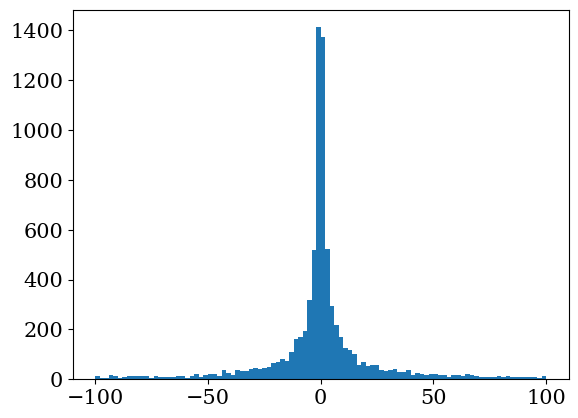

In [43]:
plt.hist(x[0]/(10**-45)-x[1]*10**7,bins=100,range=(-100.1,100.1))

In [10]:
a=[]
for i in range(1,1001):
    a.append(test('/data/neutrinos/scratch/pingal/GiBUU2023/release2023/case2/'+str(i)+'/FinalEvents.dat','/data/neutrinos/scratch/pingal/GiBUU2023/release2023/case2/'+str(i)+'/PertParticles_Init_ALL.dat')) 

In [11]:
a[0][8]

<Array [0.967, 1.31, 1.07, 1.22, ..., 1.02, 0.957, 2.23] type='9496 * float64'>

In [19]:
xi=np.array([])
yi=np.array([])
zi=np.array([])
Ei=np.array([])
pxi=np.array([])
pyi=np.array([])
pzi=np.array([])
Es= ak.ArrayBuilder()
pxs= ak.ArrayBuilder()
pys= ak.ArrayBuilder()
pzs= ak.ArrayBuilder()
ID = ak.ArrayBuilder()
for i in range(1,1001):
    ID.append(ak.Array(a[i-1][0]))
    Es.append(ak.Array(a[i-1][1]))
    pxs.append(ak.Array(a[i-1][2]))
    pys.append(ak.Array(a[i-1][3]))
    pzs.append(ak.Array(a[i-1][4]))      
    xi=np.append(xi,np.array(a[i-1][5]))
    yi=np.append(yi,np.array(a[i-1][6]))
    zi=np.append(zi,np.array(a[i-1][7]))
    Ei=np.append(Ei,np.array(a[i-1][8]))    
    pxi=np.append(pxi,np.array(a[i-1][9]))
    pyi=np.append(pyi,np.array(a[i-1][10]))
    pzi=np.append(pzi,np.array(a[i-1][11]))    

(array([3.94200e+03, 1.11610e+04, 1.85330e+04, 2.57440e+04, 3.30200e+04,
        3.99090e+04, 4.69710e+04, 5.42430e+04, 6.10480e+04, 6.83560e+04,
        7.49240e+04, 8.18830e+04, 8.89420e+04, 9.51390e+04, 1.01952e+05,
        1.08379e+05, 1.14538e+05, 1.21242e+05, 1.27746e+05, 1.33494e+05,
        1.38779e+05, 1.43827e+05, 1.50061e+05, 1.54503e+05, 1.60620e+05,
        1.64867e+05, 1.69153e+05, 1.73493e+05, 1.77450e+05, 1.80890e+05,
        1.85012e+05, 1.87942e+05, 1.90824e+05, 1.92266e+05, 1.94378e+05,
        1.96057e+05, 1.97364e+05, 1.98127e+05, 1.97647e+05, 1.97424e+05,
        1.97778e+05, 1.96122e+05, 1.94522e+05, 1.92487e+05, 1.89942e+05,
        1.87819e+05, 1.83978e+05, 1.80773e+05, 1.76574e+05, 1.72524e+05,
        1.67014e+05, 1.61691e+05, 1.57171e+05, 1.50303e+05, 1.44570e+05,
        1.39299e+05, 1.32494e+05, 1.26807e+05, 1.20184e+05, 1.14231e+05,
        1.07671e+05, 1.00559e+05, 9.40760e+04, 8.87650e+04, 8.21540e+04,
        7.66150e+04, 7.12610e+04, 6.61010e+04, 6.01

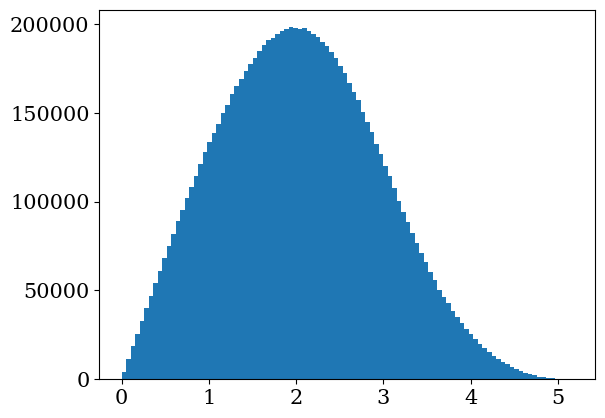

In [13]:
plt.hist(np.sqrt(xi**2+yi**2+zi**2),bins=100)

Text(0.5, 0, '|p| [GeV/c]')

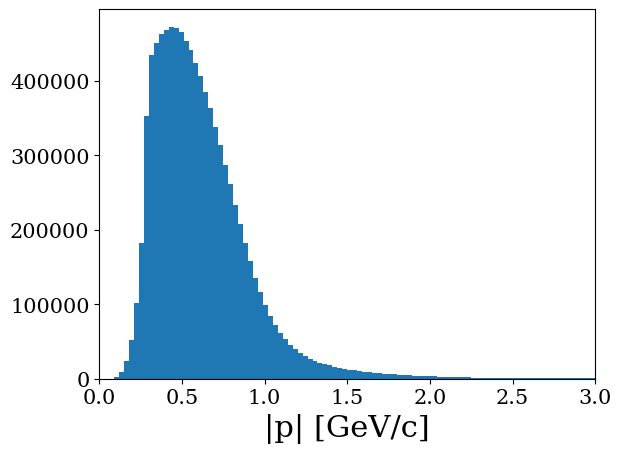

In [36]:
plt.hist(np.sqrt(pxi**2+pyi**2+pzi**2),bins=100,range=(0,3))
plt.xlim(0,3)
plt.xlabel("|p| [GeV/c]")

Text(0.5, 0, 'E [GeV]')

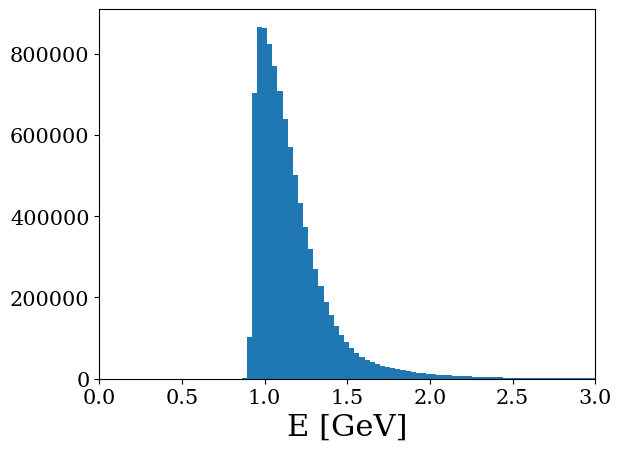

In [38]:
plt.hist(Ei,bins=100,range=(-0.1,3))
plt.xlim(0,3)
plt.xlabel("E [GeV]")

Text(0.5, 0, 'SQRT(p.p)')

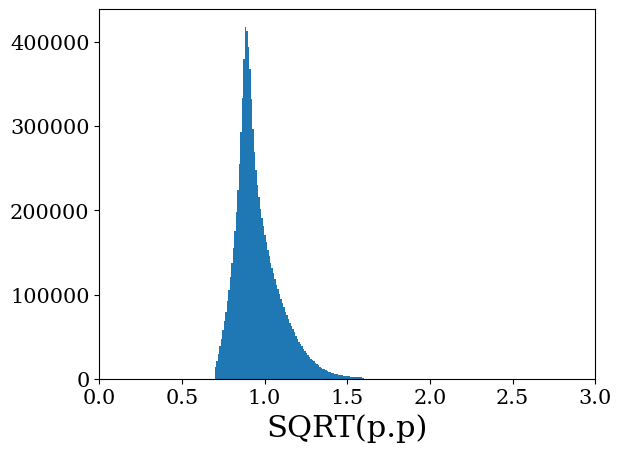

In [18]:
plt.hist(np.sqrt(Ei**2-(pxi**2+pyi**2+pzi**2)),bins=100,range=(0.7,1.6))
plt.xlim(0,3)
plt.xlabel("SQRT(p.p)")

In [25]:
ID2=ak.flatten(ID.snapshot(),axis=1)
pxs2=ak.flatten(pxs.snapshot(),axis=1)
pys2=ak.flatten(pys.snapshot(),axis=1)
pzs2=ak.flatten(pzs.snapshot(),axis=1)


(array([1.76000e+02, 1.04900e+03, 2.82100e+03, 5.59100e+03, 9.20600e+03,
        1.36360e+04, 1.89040e+04, 2.47010e+04, 3.13030e+04, 3.85320e+04,
        4.64470e+04, 5.53480e+04, 6.38820e+04, 7.30720e+04, 8.20210e+04,
        9.20560e+04, 1.02507e+05, 1.12939e+05, 1.23244e+05, 1.32962e+05,
        1.43852e+05, 1.54531e+05, 1.63688e+05, 1.74357e+05, 1.83777e+05,
        1.93339e+05, 2.03919e+05, 2.12362e+05, 2.20989e+05, 2.28766e+05,
        2.37366e+05, 2.43625e+05, 2.51043e+05, 2.57027e+05, 2.61964e+05,
        2.67356e+05, 2.71759e+05, 2.73750e+05, 2.78867e+05, 2.79784e+05,
        2.82222e+05, 2.81055e+05, 2.81588e+05, 2.80048e+05, 2.76939e+05,
        2.73632e+05, 2.68338e+05, 2.62559e+05, 2.55257e+05, 2.46269e+05,
        2.35564e+05, 2.21139e+05, 2.06485e+05, 1.88171e+05, 1.65342e+05,
        1.35530e+05, 9.34940e+04, 1.18980e+04, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00000e+00,
        0.00000e+00, 0.00000e+00, 0.00000e+00, 0.00

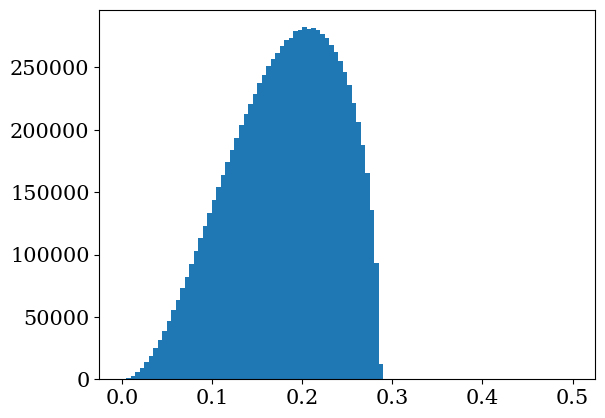

In [26]:
plt.hist(np.sqrt(pxs2[:,1]*pxs2[:,1]+pys2[:,1]*pys2[:,1]+pzs2[:,1]*pzs2[:,1]),bins=100,range=(0,0.5))

In [27]:
np.sqrt(pxs2[:,1]*pxs2[:,1]+pys2[:,1]*pys2[:,1]+pzs2[:,1]*pzs2[:,1])

<Array [0.191, 0.0826, 0.216, ..., 0.163, 0.238] type='9498048 * float64'>

In [15]:
At=test('/data/neutrinos/scratch/pingal/GiBUU2023/release2023/case2/1/FinalEvents.dat','/data/neutrinos/scratch/pingal/GiBUU2023/release2023/case2/1/PertParticles_Init_ALL.dat')

In [16]:
At[8],At[9],At[10]

(<Array [0.967, 1.31, 1.07, 1.22, ..., 1.02, 0.957, 2.23] type='9496 * float64'>,
 <Array [-0.143, 0.193, 0.439, ..., 0.000733, -0.344] type='9496 * float64'>,
 <Array [-0.168, -0.0433, 0.342, ..., 0.216, 0.159, 0.487] type='9496 * float64'>)

In [17]:
At[1]

<Array [[0.402, 0.912, 0.967], ..., [2.43, ...]] type='9496 * var * float64'>

In [31]:
At[0]

<Array [[902, 1, 1], [902, ...], ..., [902, 1, 1, 1]] type='9496 * var * int64'>

In [18]:
!head -200 /data/neutrinos/scratch/pingal/GiBUU2023/release2023/case2/1/FinalEvents.dat

# 1:Run  2:Event  3:ID 4:Charge     5:perweight   6:position(1)   7:position(2)   8:position(3)   9:momentum(0)  10:momentum(1)  11:momentum(2)  12:momentum(3)     13:history  14:production_ID  15:enu
      1      1    902     -1  3.173206E-05  0.000000E+00  0.000000E+00  0.000000E+00  3.537650E-01  1.577355E-01  2.983906E-01 -8.259763E-03          0   1  5.358166E-01
      1      1      1      0  0.000000E+00  0.000000E+00  0.000000E+00  0.000000E+00  9.221974E-01  3.679982E-02 -7.380464E-02 -7.249727E-02          0   1  5.358166E-01
      1      1      1      1  3.173206E-05 -7.324869E-01 -8.933662E+00  1.169924E+01  1.104305E+00 -1.364177E-01 -3.608582E-01  4.532933E-01          0   1  5.358166E-01
      1      2    902     -1  4.195013E-08  0.000000E+00  0.000000E+00  0.000000E+00  2.320441E-01  1.464436E-01 -1.185804E-01  8.469583E-02          0   1  6.009249E-01
      1      2      1      0  0.000000E+00  0.000000E+00  0.000000E+00  0.000000E+00  9.265388E-01  1.647106E-01 -1.063

In [21]:
!head -270 /data/neutrinos/scratch/pingal/GiBUU2023/release2023/case2/1/PertParticles_Init_ALL.dat

Ensemb| Index[   Number]: ID IQ Anti mass | momentum(0:3) | position(1:3) | ScaleCS firstEvent [event] perWeight, max(-9.9d0,formationTime), productionTime,lastCollisionTime, in_Formation, parents
     1|     1[   100130]:  1  1 F   1.088 |  1.1773352E+00  6.0495134E-02  2.1470480E-01  4.4810408E-01|  1.320E+00 -2.124E+00 -4.057E-02| 1.000       119[   100008   100008]   6.933E-08 time:   -9.900    0.000    0.000 F parents:   0   0   0
     1|     2[   100012]:  1  1 F   0.930 |  1.1042489E+00 -1.2093571E-01 -3.7219522E-01  4.7157905E-01|  2.218E+00 -1.065E+00  1.810E+00| 1.000         1[   100002   100002]   3.173E-05 time:   -9.900    0.000    0.000 F parents:   0   0   0
     1|     3[   100013]:  1  1 F   1.271 |  1.2954196E+00  1.8267014E-02  1.2253867E-02  3.7946184E-01|  2.083E+00 -9.144E-01 -1.957E-01| 1.000         2[   100004   100004]   4.195E-08 time:   -9.900    0.000    0.000 F parents:   0   0   0
     1|     4[   100014]:  1  1 F   0.937 |  9.6925881E-01  2.2951614E-01 

In [34]:
test('/data/neutrinos/scratch/pingal/GiBUU2023/release2023/case2/1/FinalEvents.dat','/data/neutrinos/scratch/pingal/GiBUU2023/release2023/case2/1/PertParticles_Init_ALL.dat')

(<Array [[902, 1, 1], [902, ...], ..., [902, 1, 1, 1]] type='9496 * var * int64'>,
 <Array [[0.402, 0.912, 0.967], ..., [2.43, ...]] type='9496 * var * float64'>,
 <Array [[0.0894, -0.0536, -0.0377], ..., [...]] type='9496 * var * float64'>,
 <Array [[0.283, 0.114, -0.144], ..., [-0.238, ...]] type='9496 * var * float64'>,
 <Array [[0.25, 0.143, 0.305], ..., [2.39, ...]] type='9496 * var * float64'>,
 <Array [-1.11, -0.114, -0.233, ..., 1.04, -0.871, -0.434] type='9496 * float64'>,
 <Array [-1.79, 0.252, -1.6, ..., 1.95, 0.771, -0.566] type='9496 * float64'>,
 <Array [-1.79, 0.252, -1.6, ..., 1.95, 0.771, -0.566] type='9496 * float64'>,
 <Array [0.967, 1.31, 1.07, 1.22, ..., 1.02, 0.957, 2.23] type='9496 * float64'>,
 <Array [-0.143, 0.193, 0.439, ..., 0.000733, -0.344] type='9496 * float64'>,
 <Array [-0.168, -0.0433, 0.342, ..., 0.216, 0.159, 0.487] type='9496 * float64'>,
 <Array [0.351, 0.511, 0.404, ..., 0.273, 0.299, 1.53] type='9496 * float64'>)